In [1]:
print("Welcome to my ML Classification Project!")
print("python enviroment is ready")

Welcome to my ML Classification Project!
python enviroment is ready


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breats_cancer

print("Libraries imported successfully!")

ImportError: cannot import name 'load_breats_cancer' from 'sklearn.datasets' (f:\ML_CLASSICIFICATION_PROJECT\venv\Lib\site-packages\sklearn\datasets\__init__.py)

In [4]:
# Day 1: Load and explore the Breast Cancer Wisconsin dataset

import pandas as pd
from sklearn.datasets import load_breast_cancer

# 1. Load the dataset (built into scikit-learn)
data = load_breast_cancer()

# 2. Put it into a pandas DataFrame (a table)
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

# 3. Basic exploration
print("Shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nTarget names:", data.target_names)
print("\nClass counts:")
print(df["target"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

# 4. Save a copy for later use
import os

os.makedirs("data", exist_ok=True)   # creates the folder if it's missing
df.to_csv("data/breast_cancer.csv", index=False)
print("\nSaved to data/breast_cancer.csv")

Shape (rows, columns): (569, 31)

First 5 rows:
   mean radius  mean texture  ...  worst fractal dimension  target
0        17.99         10.38  ...                  0.11890       0
1        20.57         17.77  ...                  0.08902       0
2        19.69         21.25  ...                  0.08758       0
3        11.42         20.38  ...                  0.17300       0
4        20.29         14.34  ...                  0.07678       0

[5 rows x 31 columns]

Target names: ['malignant' 'benign']

Class counts:
target
1    357
0    212
Name: count, dtype: int64

Missing values: 0

Saved to data/breast_cancer.csv


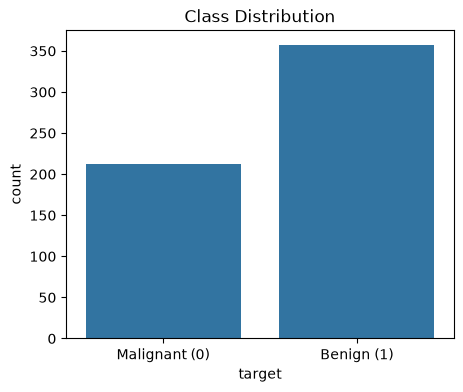

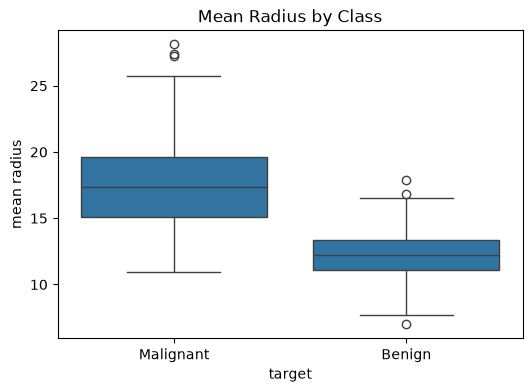

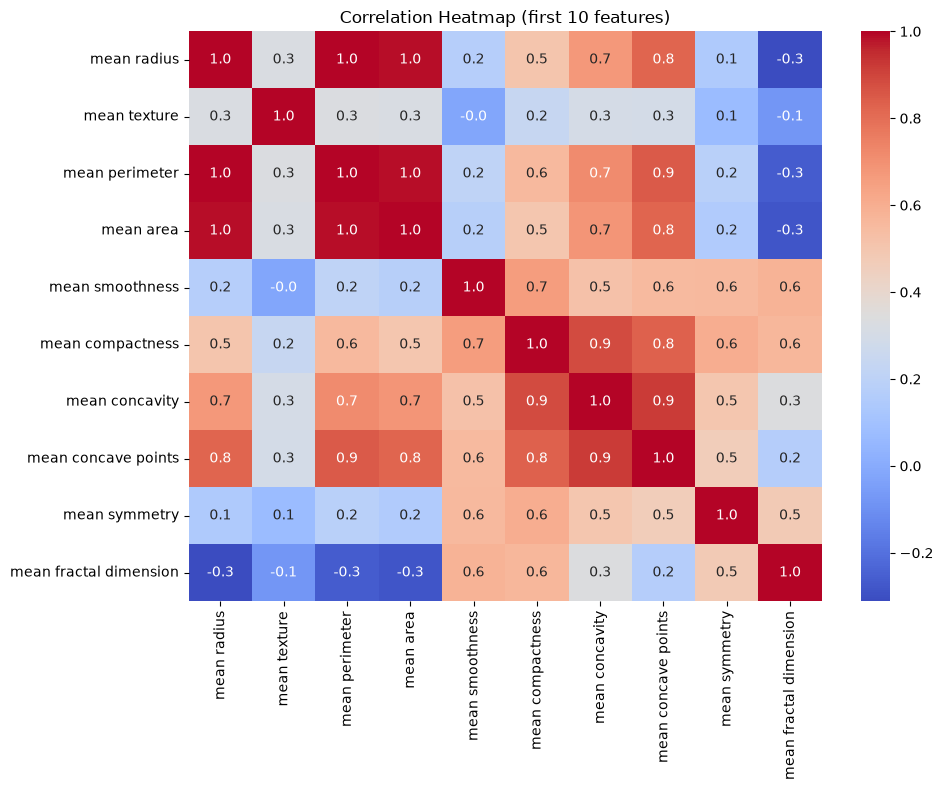

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

# Load data again (same as Day 1)
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

os.makedirs("outputs", exist_ok=True)   # use "../outputs" if you're inside notebooks/

# Plot 1: Class distribution
plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=df)
plt.xticks([0, 1], ["Malignant (0)", "Benign (1)"])
plt.title("Class Distribution")
plt.savefig("outputs/class_distribution.png")
plt.show()

# Plot 2: One feature compared across classes
plt.figure(figsize=(6, 4))
sns.boxplot(x="target", y="mean radius", data=df)
plt.xticks([0, 1], ["Malignant", "Benign"])
plt.title("Mean Radius by Class")
plt.savefig("outputs/mean_radius_boxplot.png")
plt.show()

# Plot 3: Correlation heatmap of the first 10 features
plt.figure(figsize=(10, 8))
sns.heatmap(df.iloc[:, :10].corr(), annot=True, fmt=".1f", cmap="coolwarm")
plt.title("Correlation Heatmap (first 10 features)")
plt.tight_layout()
plt.savefig("outputs/correlation_heatmap.png")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate features (X) and the answer we want to predict (y)
X = df.drop("target", axis=1)
y = df["target"]

# 2. Split: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn from training data AND transform it
X_test_scaled = scaler.transform(X_test)         # only transform, never learn from test data

print("Training set:", X_train_scaled.shape)
print("Testing set:", X_test_scaled.shape)
print("\nTrain class counts:\n", y_train.value_counts())
print("\nTest class counts:\n", y_test.value_counts())

Training set: (455, 30)
Testing set: (114, 30)

Train class counts:
 target
1    285
0    170
Name: count, dtype: int64

Test class counts:
 target
1    72
0    42
Name: count, dtype: int64


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. Create the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}

# 2. Train each model and check its accuracy
for name, model in models.items():
    model.fit(X_train_scaled, y_train)               # learn from training data
    train_acc = model.score(X_train_scaled, y_train)  # accuracy on data it has seen
    test_acc = model.score(X_test_scaled, y_test)     # accuracy on unseen data

    print(f"{name}")
    print(f"  Train accuracy: {train_acc:.4f}")
    print(f"  Test accuracy:  {test_acc:.4f}\n")

Logistic Regression
  Train accuracy: 0.9890
  Test accuracy:  0.9825

KNN
  Train accuracy: 0.9736
  Test accuracy:  0.9561

Decision Tree
  Train accuracy: 1.0000
  Test accuracy:  0.9123



Logistic Regression
Confusion matrix:
[[41  1]
 [ 1 71]]

Classification report:
               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



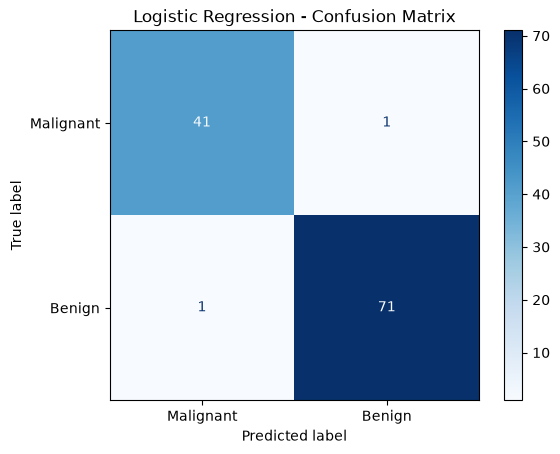

KNN
Confusion matrix:
[[39  3]
 [ 2 70]]

Classification report:
               precision    recall  f1-score   support

Malignant (0)       0.95      0.93      0.94        42
   Benign (1)       0.96      0.97      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.95      0.95       114
 weighted avg       0.96      0.96      0.96       114



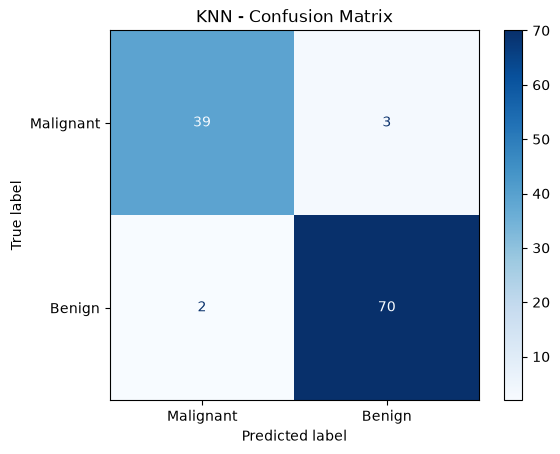

Decision Tree
Confusion matrix:
[[39  3]
 [ 7 65]]

Classification report:
               precision    recall  f1-score   support

Malignant (0)       0.85      0.93      0.89        42
   Benign (1)       0.96      0.90      0.93        72

     accuracy                           0.91       114
    macro avg       0.90      0.92      0.91       114
 weighted avg       0.92      0.91      0.91       114



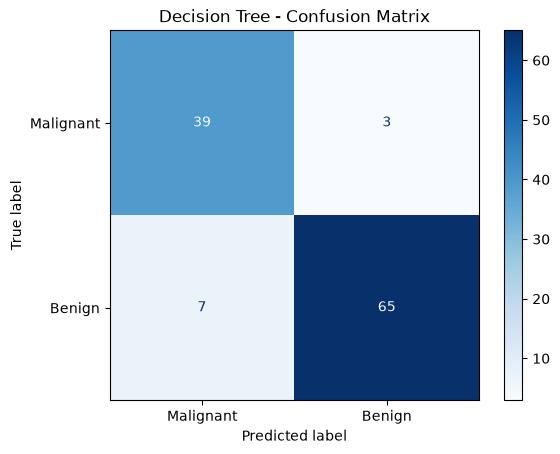

In [8]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    print("=" * 50)
    print(name)
    print("=" * 50)
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification report:")
    print(classification_report(
        y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"]
    ))

    # Plot the confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["Malignant", "Benign"],
        cmap="Blues"
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.savefig(f"outputs/confusion_matrix_{name.replace(' ', '_').lower()}.png")
    plt.show()

In [9]:
from sklearn.tree import DecisionTreeClassifier

for depth in [2, 3, 4, 5, 6, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train_scaled, y_train)
    train_acc = tree.score(X_train_scaled, y_train)
    test_acc = tree.score(X_test_scaled, y_test)
    print(f"max_depth={str(depth):5} | Train: {train_acc:.4f} | Test: {test_acc:.4f}")

max_depth=2     | Train: 0.9582 | Test: 0.8947
max_depth=3     | Train: 0.9758 | Test: 0.9386
max_depth=4     | Train: 0.9868 | Test: 0.9386
max_depth=5     | Train: 0.9934 | Test: 0.9211
max_depth=6     | Train: 0.9978 | Test: 0.9123
max_depth=None  | Train: 1.0000 | Test: 0.9123


In [10]:
import os
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Build a pipeline: scale first, then classify
best_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

# 2. Train on the ORIGINAL (unscaled) data, since the pipeline scales internally
best_model.fit(X_train, y_train)
print("Test accuracy:", best_model.score(X_test, y_test))

# 3. Save it
os.makedirs("models", exist_ok=True)   # use "../models" if you're inside notebooks/
joblib.dump(best_model, "models/breast_cancer_model.pkl")
print("Model saved!")

# 4. Load it back and predict for one patient
loaded_model = joblib.load("models/breast_cancer_model.pkl")
sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
print("Prediction:", "Benign" if prediction == 1 else "Malignant")
print("Actual:    ", "Benign" if y_test.iloc[0] == 1 else "Malignant")

Test accuracy: 0.9824561403508771
Model saved!
Prediction: Malignant
Actual:     Malignant


In [11]:
# Breast Cancer Classification

A machine learning project that predicts whether a tumor is malignant or
benign using the Breast Cancer Wisconsin dataset.

## Dataset
- 569 samples, 30 numerical features (radius, texture, area, etc.)
- Classes: Malignant (212) and Benign (357)
- Source: built into scikit-learn

## Steps
1. Loaded and explored the data
2. Visualized class balance, feature differences, and correlations
3. Split into 80% train / 20% test (stratified) and scaled the features
4. Trained Logistic Regression, KNN, and Decision Tree
5. Evaluated with confusion matrix, precision, recall, and F1-score
6. Reduced Decision Tree overfitting with max_depth
7. Saved the best model

## Results
| Model | Test Accuracy | Missed Malignant Cases |
|---|---|---|
| Logistic Regression | 98.25% | 1 of 42 |
| KNN | 95.61% | 3 of 42 |
| Decision Tree | 91.23% | 3 of 42 |

**Best model:** Logistic Regression.

## Tools
Python, pandas, NumPy, matplotlib, seaborn, scikit-learn

## How to run
```bash
python -m venv venv
venv\Scripts\activate
pip install -r requirements.txt
```

## Author
Your Name, B.Tech CSE (AI)

SyntaxError: invalid syntax (2505771878.py, line 3)